<a href="https://colab.research.google.com/github/ayobami4/TechCrush-Cohort-9_AI-ML/blob/main/Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Import
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__) # This is to check the TensorFlow version
tf.random.set_seed(234)   # This is to set a random seed for reproducibility

TensorFlow version: 2.21.0


In [2]:
# Here is the sample data consisting of just 10 samples
# X is the feature with each sample having record of study hours and sleep hours
# For example first observation is [1, 4] i.e, study hours = 1, sleep hours = 4
# second observation is [2, 5], i.e, study hours = 2, sleep hours = 5 and so on

X = np.array([[1, 4], [2, 5], [3, 6], [4, 5], [5, 7],
              [6, 6], [7, 8], [8, 7], [9, 8], [10, 7]], dtype="float32")

# This is the label for all 10 samples
# y is one value per sample: 0 means fail and 1 means pass
# first-four samples failed(0) and last six sample passed(1)
y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1], dtype="float32")


### Complete the following task

In [3]:
# 2. Build the model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

In [4]:
# 3. Inspect the model parameters with summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 4. Compile

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [6]:
# 5. Train

history = model.fit(X, y, epochs=100, batch_size=20)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 1.0902
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.5000 - loss: 1.0834
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5000 - loss: 1.0767
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.5000 - loss: 1.0700
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5000 - loss: 1.0633
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.5000 - loss: 1.0567
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.5000 - loss: 1.0501
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.5000 - loss: 1.0435
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.5000 - loss: 1.0369
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.5000 - loss: 1.0304
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.5000 - loss: 1.0239
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.50

In [9]:
# 6. Predict: 6 hours study, 7 hours sleep

X_test = np.array([[6, 7]], dtype="float32")
actual_prediction = model.predict(X_test)

simplified_prediction = 1 if actual_prediction > 0.5 else 0

print("Actual prediction:", actual_prediction)
print("Simplified prediction:", simplified_prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Actual prediction: [[0.2493351]]
Simplified prediction: 0


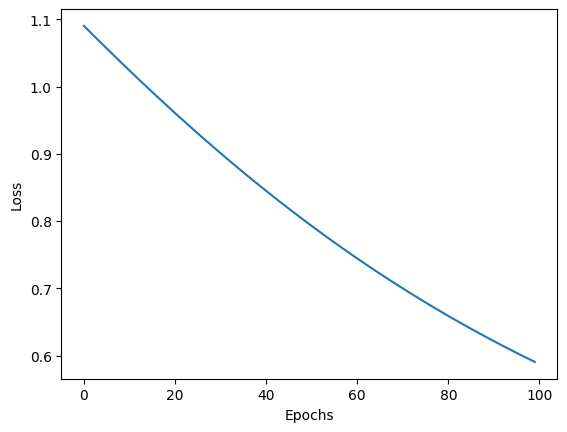

In [10]:
# 7. Loss plot

plt.plot(history.history["loss"])
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()